# Oracle IDM, T1

A perfect video model hands us the future frame: can a small model read the actions off it?
Here the future is the real one (sim rewound and replayed). Later steps degrade it, to find how
precise a dream has to be, and where.


In [3]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/idm_nb')

## Step 0: data

Joints, actions, demo ids, top-camera frames (the same cache as `lam.ipynb`).


In [4]:
import numpy as np
from uwm_parts import load_table

NAME = 'pick_place_cube_n100'
state, action, episode = load_table(NAME)
top = np.load(f'../cache/lam/{NAME}_top.npy')  # [N, 3, 128, 128] uint8
print(f'{top.shape=}  {state.shape=}  {action.shape=}  demos {episode.max() + 1}')

top.shape=(21295, 3, 128, 128)  state.shape=(21295, 8)  action.shape=(21295, 8)  demos 100


## Step 1: what the IDM reads

Frame t and frame t+10; its answer is the 10 actions in between.


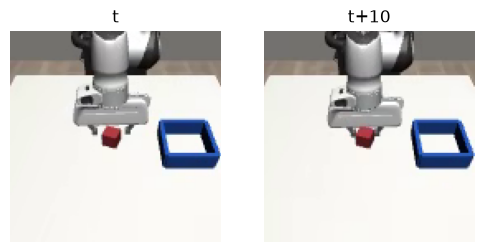

In [5]:
import matplotlib.pyplot as plt

K = 10  # steps between the two frames = actions to read
t = np.flatnonzero(episode == 31)[0] + 60
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
for ax, i, name in zip(axs, [t, t + K], ['t', f't+{K}']):
    ax.imshow(top[i].transpose(1, 2, 0))
    ax.set_title(name)
    ax.axis('off')

In [6]:
print('state t     ', state[t].round(3))
print('actions     ', action[t : t + K, 0].round(3), '(joint 0)')
print('gripper     ', action[t : t + K, 7])
print('state t+10  ', state[t + K].round(3))

state t      [-0.041  0.798  0.013 -2.189 -0.017  3.102  0.741  0.992]
actions      [-0.041 -0.041 -0.041 -0.041 -0.041 -0.041 -0.041 -0.041 -0.041 -0.041] (joint 0)
gripper      [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
state t+10   [-0.041  0.822  0.013 -2.175 -0.017  3.1    0.741  0.66 ]


## Step 2: no-learning baselines

Val demos, squared error on the 7 arm joints. hold = keep the joints of frame t;
interp = straight line to the joints at t+10 (a cheat: the IDM never sees future joints).


In [7]:
val = np.random.default_rng(0).permutation(100)[:10]  # lam / dreamzero's held-out demos
ok = np.flatnonzero(episode[:-K] == episode[K:])  # rows t with t+10 in the same demo
r = ok[np.isin(episode[ok], val)]
chunk = action[r[:, None] + np.arange(K)]  # [n, 10, 8]: the answer
print(len(r), 'val rows')

2039 val rows


In [8]:
hold = state[r][:, None]
print(f'hold   arm {((hold - chunk)[..., :7] ** 2).mean():.5f}')

hold   arm 0.00358


In [9]:
w = (np.arange(1, K + 1) / K)[None, :, None]
interp = (1 - w) * state[r][:, None] + w * state[r + K][:, None]
print(f'interp arm {((interp - chunk)[..., :7] ** 2).mean():.5f}')

interp arm 0.00084


## Step 3: the encoder

Each frame alone through the same 3 stride-2 convs: 128 -> 16, one map per keypoint.


In [22]:
import torch
from torch import nn

dev = 'cuda'
C = 32  # keypoints per frame


def down(i, o):
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 3, stride=2, padding=1), nn.GroupNorm(8, o), nn.GELU())


enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 64), nn.Conv2d(64, C, 1)).to(dev)


def frames(rows):
    # rows -> [B, 3, 128, 128] float in [0, 1] on the GPU
    return torch.tensor(top[rows], device=dev).float() / 255

In [23]:
with torch.no_grad():
    maps = enc(frames(r[:3]))
print(maps.shape)

torch.Size([3, 32, 16, 16])


Spatial softmax: each map becomes one point, the softmax-weighted (x, y). Position survives,
which a plain average over the map would throw away.


In [24]:
def keypoints(maps):
    # [B, C, h, w] -> [B, C, 2]: each channel's softmax-weighted (x, y), in [-1, 1]
    B, _, h, w = maps.shape
    p = maps.flatten(2).softmax(-1).unflatten(2, (h, w))
    xs, ys = torch.linspace(-1, 1, w, device=dev), torch.linspace(-1, 1, h, device=dev)
    return torch.stack([(p.sum(2) * xs).sum(-1), (p.sum(3) * ys).sum(-1)], -1)

In [25]:
print(keypoints(maps).shape)
print(keypoints(maps)[0, :3])

torch.Size([3, 32, 2])
tensor([[ 0.0156, -0.0249],
        [-0.0034, -0.0452],
        [ 0.0141, -0.0520]], device='cuda:0')


## Step 4: the head

Keypoints of frame t, of frame t+10, their difference, and the joints now -> 10 actions.
Inputs and targets in std units of the 90 training demos.


In [26]:
tr = ok[~np.isin(episode[ok], val)]  # training rows
s_mean, s_std = state[tr].mean(0), state[tr].std(0)
a_mean, a_std = action[tr].mean(0), action[tr].std(0)
print(len(tr), 'train rows')

18256 train rows


In [27]:
head = nn.Sequential(
    nn.Linear(3 * C * 2 + 8, 256),
    nn.GELU(),
    nn.Linear(256, 256),
    nn.GELU(),
    nn.Linear(256, K * 8),
).to(dev)

In [28]:
rows = r[:3]
with torch.no_grad():
    now = keypoints(enc(frames(rows))).flatten(1)
    fut = keypoints(enc(frames(rows + K))).flatten(1)
    joints = torch.tensor((state[rows] - s_mean) / s_std, device=dev)
    out = head(torch.cat([now, fut, fut - now, joints], 1)).view(-1, K, 8)
print(now.shape, joints.shape, out.shape)

torch.Size([3, 64]) torch.Size([3, 8]) torch.Size([3, 10, 8])


## Step 5: pack into a class

Steps 3-4's pieces as one `IDM` module; same weights must give the same actions.


In [58]:
class IDM(nn.Module):
    # step 3's encoder + step 4's head
    def __init__(self, k=K):  # k: steps between the frames = actions out
        super().__init__()
        self.k = k
        self.enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 64), nn.Conv2d(64, C, 1))
        self.head = nn.Sequential(
            nn.Linear(3 * C * 2 + 8, 256),
            nn.GELU(),
            nn.Linear(256, 256),
            nn.GELU(),
            nn.Linear(256, k * 8),
        )

    def forward(self, f0, f1, joints):
        # frames t, t+k [B, 3, 128, 128], joints [B, 8] (std units) -> actions [B, k, 8] (std units)
        now = keypoints(self.enc(f0)).flatten(1)
        fut = keypoints(self.enc(f1)).flatten(1)
        return self.head(torch.cat([now, fut, fut - now, joints], 1)).view(-1, self.k, 8)

In [84]:
packed = IDM().to(dev)
packed.enc.load_state_dict(enc.state_dict())
packed.head.load_state_dict(head.state_dict())
with torch.no_grad():
    diff = (packed(frames(rows), frames(rows + K), joints) - out).abs().max()
print(f'max diff vs loose pieces: {diff.item()}')

max diff vs loose pieces: 0.0


## Step 6: train

Squared error on the 10 actions (std units). Every 1000 steps, on 512 val rows: arm squared
error in joint units (hold 0.00358, interp 0.00084) and how often the gripper command is right
(open/close at 0.5).


In [91]:
from frozendict import frozendict


@cache
def train_idm(
    steps: int = 10000, B: int = 64, lr: float = 1e-3, seed: int = 0, k: int = K, extra=None
):
    # a fresh IDM on k-step gaps -> weights (CPU), log rows [step, train loss, val arm error, gripper right]
    # extra: rollout rows (now, fut, state, act), half of every batch
    gap_ok = np.flatnonzero(episode[:-k] == episode[k:])  # rows t with t+k in the same demo
    in_val = np.isin(episode[gap_ok], val)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = IDM(k).to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(gap_ok[in_val], 512, replace=False)
    v0, v1 = frames(vr), frames(vr + k)
    vj = torch.tensor((state[vr] - s_mean) / s_std, device=dev)
    va = action[vr[:, None] + np.arange(k)]
    log = []
    for step in range(1, steps + 1):
        b = rng.choice(gap_ok[~in_val], B)
        f0, f1 = frames(b), frames(b + k)
        st, acts = state[b], action[b[:, None] + np.arange(k)]
        if extra is not None:
            h = B // 2
            e = rng.integers(0, len(extra['act']), B - h)
            f0[h:] = torch.tensor(extra['now'][e], device=dev).float() / 255
            f1[h:] = torch.tensor(extra['fut'][e], device=dev).float() / 255
            st = np.concatenate([st[:h], extra['state'][e]])
            acts = np.concatenate([acts[:h], extra['act'][e]])
        jb = torch.tensor((st - s_mean) / s_std, device=dev)
        target = torch.tensor((acts - a_mean) / a_std, device=dev)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (net(f0, f1, jb).float() - target).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            with torch.no_grad():
                pred = net(v0, v1, vj).cpu().numpy() * a_std + a_mean
            arm = ((pred - va)[..., :7] ** 2).mean()
            grip = ((pred[..., 7] > 0.5) == (va[..., 7] > 0.5)).mean()
            log.append([step, loss.item(), arm, grip])
            print(f'{step:5d}  train {loss:.4f}   val arm {arm:.5f}  gripper right {grip:.1%}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_idm: cached, 2 call(s) stored


In [89]:
run = train_idm()

train_idm: result copied by keep=True from older code (cell 7194a6abda2b)
 1000  train 0.0077   val arm 0.00011  gripper right 99.1%
 2000  train 0.0067   val arm 0.00008  gripper right 99.3%
 3000  train 0.0068   val arm 0.00006  gripper right 99.5%
 4000  train 0.0041   val arm 0.00006  gripper right 99.6%
 5000  train 0.0045   val arm 0.00005  gripper right 99.5%
 6000  train 0.0031   val arm 0.00004  gripper right 99.6%
 7000  train 0.0039   val arm 0.00004  gripper right 99.6%
 8000  train 0.0026   val arm 0.00004  gripper right 99.5%
 9000  train 0.0023   val arm 0.00004  gripper right 99.6%
10000  train 0.0025   val arm 0.00003  gripper right 99.5%


## Step 7: the gripper where it matters

99.5% counts the many chunks where the command never changes. Score the chunks where it flips
(grasp, release) apart from the steady ones.


In [85]:
net = IDM().to(dev)
net.load_state_dict(run['weights'])
with torch.no_grad():
    pred = torch.cat(
        [
            net(frames(b), frames(b + K), torch.tensor((state[b] - s_mean) / s_std, device=dev))
            for b in np.array_split(r, 16)
        ]
    )
pred = pred.cpu().numpy() * a_std + a_mean  # [n, 10, 8] all val rows, joint units

In [34]:
right = (pred[..., 7] > 0.5) == (chunk[..., 7] > 0.5)  # [n, 10]
flips = (chunk[:, 1:, 7] != chunk[:, :-1, 7]).any(1)
print(
    f'{flips.sum()} chunks with a flip: right {right[flips].mean():.1%}   whole chunk right {right[flips].all(1).mean():.1%}'
)
print(
    f'{(~flips).sum()} steady chunks:  right {right[~flips].mean():.1%}   whole chunk right {right[~flips].all(1).mean():.1%}'
)

170 chunks with a flip: right 95.6%   whole chunk right 60.0%
1869 steady chunks:  right 100.0%   whole chunk right 99.7%


## Step 8: the sim and the expert

T1's scripted expert: a phase machine (approach, descend, grasp, lift, ...) reading the live sim.


In [36]:
from uwm_parts import make_sim

from dream_robot.sims.robosuite.tasks.pick_place_cube.expert import ExpertPolicy

env = make_sim()
expert = ExpertPolicy(env)


def play(obs, n):
    # the expert plays n steps from obs -> the last observation
    for _ in range(n):
        obs = env.step(expert(obs)[0]).observation
    return obs

In [37]:
obs = env.reset(seed=1000)
expert.reset()
for i in range(600):
    res = env.step(expert(obs)[0])
    obs = res.observation
    if res.terminated or res.truncated:
        break
print(f'{i + 1} steps, success {res.success}')

207 steps, success True


## Step 9: rewind, naive

The oracle's trick: save the sim, let the expert play 10 steps, keep that frame, rewind.
Check: imagine 10 steps, rewind, then play the same 10 for real. Same frame?
First try: save only MuJoCo's data (+ the expert's phase machine).


In [38]:
import copy

import mujoco

obs = env.reset(seed=1000)
expert.reset()
obs = play(obs, 60)  # near the grasp
model, data = env.mujoco
saved, machine = mujoco.MjData(model), copy.deepcopy(expert._machine)
mujoco.mj_copyData(saved, model, data)
imagined = play(obs, 10)
mujoco.mj_copyData(data, model, saved)
expert._machine = copy.deepcopy(machine)
real = play(obs, 10)
print('joints diff', np.abs(imagined.state - real.state).round(4))
print('pixel diff max', np.abs(imagined.images['top'].astype(int) - real.images['top']).max())

joints diff [0.0004 0.012  0.0003 0.007  0.0004 0.0038 0.0011 0.0085]
pixel diff max 185


## Step 10: everything the next step reads

robosuite keeps state outside MuJoCo's data:

- the gripper rate-limits its command (closes a little more each step)
- the sensors sample on their own timers
- the controllers cache their last reading of the joints
- robosuite's clock and our task wrapper's step counter (they end the episode)

Measured (joints diff after 10 steps): at the grasp, gripper alone 0.0004, gripper + sensor timers 0;
on the approach, the sensor timers alone fix it. Controllers and clock change nothing over 10 steps,
but end-of-episode needs the clock. Save all of them.
Gotcha: robosuite builds a new MuJoCo sim at every `env.reset`, so fetch `env.mujoco` each time.


In [39]:
PLAIN = (np.ndarray, bool, int, float, type(None))
CLOCK = ('timestep', 'cur_time', 'done')  # robosuite's
WRAP = ('_raw', '_t', '_max_z', '_z0', '_max_cube_z', '_cube_z0')  # our task wrapper's


def parts():
    # the robosuite objects with their own state
    robot = env._env.robots[0]
    return [
        *env._env._observables.values(),
        *robot.gripper.values(),
        *robot.composite_controller.part_controllers.values(),
    ]

In [44]:
def snapshot():
    # -> everything the next env.step reads, and the expert's phase
    model, data = env.mujoco  # new objects after every env.reset
    physics = mujoco.MjData(model)
    mujoco.mj_copyData(physics, model, data)
    fields = [{k: v for k, v in vars(p).items() if isinstance(v, PLAIN)} for p in parts()]
    clock = {f: getattr(env._env, f) for f in CLOCK}
    wrap = {f: getattr(env, f) for f in WRAP if hasattr(env, f)}
    return physics, copy.deepcopy((fields, clock, wrap, expert._machine))


def restore(snap):
    physics, rest = snap
    fields, clock, wrap, machine = copy.deepcopy(rest)
    model, data = env.mujoco
    mujoco.mj_copyData(data, model, physics)
    for p, f in zip(parts(), fields, strict=True):
        vars(p).update(f)
    vars(env._env).update(clock)
    vars(env).update(wrap)
    expert._machine = machine

In [45]:
obs = env.reset(seed=1000)
expert.reset()
obs = play(obs, 60)
snap = snapshot()
imagined = play(obs, 10)
restore(snap)
real = play(obs, 10)
print('joints diff', np.abs(imagined.state - real.state).max())
print('pixel diff max', np.abs(imagined.images['top'].astype(int) - real.images['top']).max())

joints diff 0.0
pixel diff max 0


## Step 11: the oracle loop

Every 10 steps: the expert dreams 10 steps ahead from where the robot really is, rewind;
the IDM reads (frame now, dream) -> 10 actions, and the robot plays them.
Between dreams the expert watches every real step, so its phase follows the robot.


In [64]:
def imagine(obs, k=K):
    # the expert's observation k steps ahead of obs (or where its episode ends), then rewind
    snap = snapshot()
    for _ in range(k):
        res = env.step(expert(obs)[0])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    restore(snap)
    return obs

In [65]:
@torch.no_grad()
def idm_act(net, obs, fut):
    # IDM on (frame now, dreamed frame) + joints -> [k, 8] actions in joint units
    f0 = torch.tensor(obs.images['top'], device=dev).permute(2, 0, 1)[None].float() / 255
    f1 = torch.tensor(fut.images['top'], device=dev).permute(2, 0, 1)[None].float() / 255
    joints = torch.tensor((obs.state - s_mean) / s_std, device=dev)[None]
    plan = net(f0, f1, joints)[0].cpu().numpy() * a_std + a_mean
    plan[:, 7] = plan[:, 7].clip(0, 1)
    return plan

In [66]:
def rollout(seed, net):
    # one episode, IDM driving on the oracle's dreams -> (success, failure mode)
    obs = env.reset(seed=seed)
    expert.reset()
    for t in range(600):
        if t % net.k == 0:
            plan = idm_act(net, obs, imagine(obs, net.k))
        expert(obs)  # the shadow expert sees the real step
        res = env.step(plan[t % net.k])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    return res.success, str(res.failure_mode)

In [49]:
from collections import Counter

res = {seed: rollout(seed, net) for seed in range(1000, 1020)}
print(f'oracle IDM: {sum(s for s, _ in res.values())}/20')
print('failures', Counter(m for s, m in res.values() if not s))

oracle IDM: 19/20
failures Counter({'wrong_target': 1})


## Step 12: the failure

Replay the failed seed, keeping at every dream point: the frame now, the dream, the gripper plan.


In [50]:
failed = [seed for seed, (ok, _) in res.items() if not ok]
print(failed)

[1009]


In [72]:
def rollout_log(seed, net):
    # rollout(), keeping (t, frame now, dreamed frame, planned gripper) at every dream point
    obs = env.reset(seed=seed)
    expert.reset()
    log = []
    for t in range(600):
        if t % net.k == 0:
            fut = imagine(obs, net.k)
            plan = idm_act(net, obs, fut)
            log.append((t, obs.images['top'], fut.images['top'], plan[:, 7].round(2)))
        expert(obs)
        res = env.step(plan[t % net.k])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    print(f'seed {seed}: {t + 1} steps, success {res.success}, {res.failure_mode}')
    return log

In [52]:
log = rollout_log(failed[0], net)

seed 1009: 600 steps, success False, wrong_target


Text(0, 0.5, 'now')

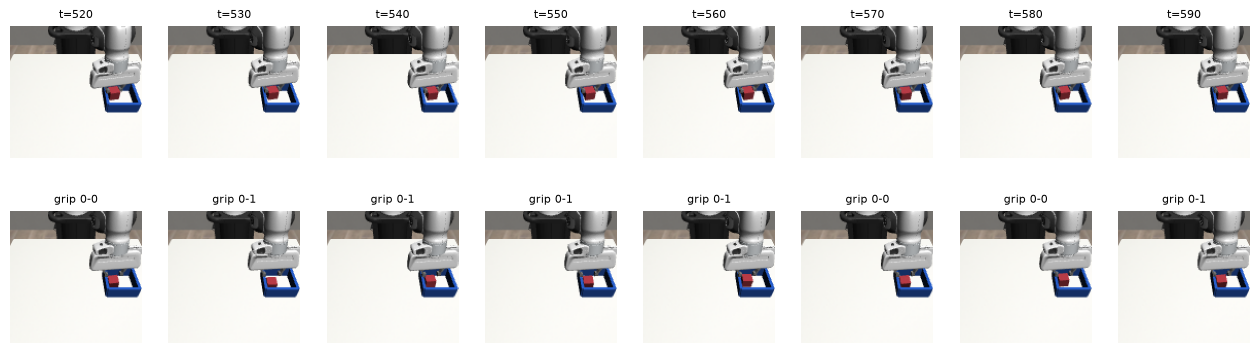

In [53]:
last = log[-8:]
fig, axs = plt.subplots(2, len(last), figsize=(2 * len(last), 4.4))
for j, (t, now, fut, grip) in enumerate(last):
    axs[0, j].imshow(now)
    axs[0, j].set_title(f't={t}', fontsize=8)
    axs[1, j].imshow(fut)
    axs[1, j].set_title(f'grip {grip.min():.0f}-{grip.max():.0f}', fontsize=8)
for ax in axs.flat:
    ax.axis('off')
axs[0, 0].set_ylabel('now')

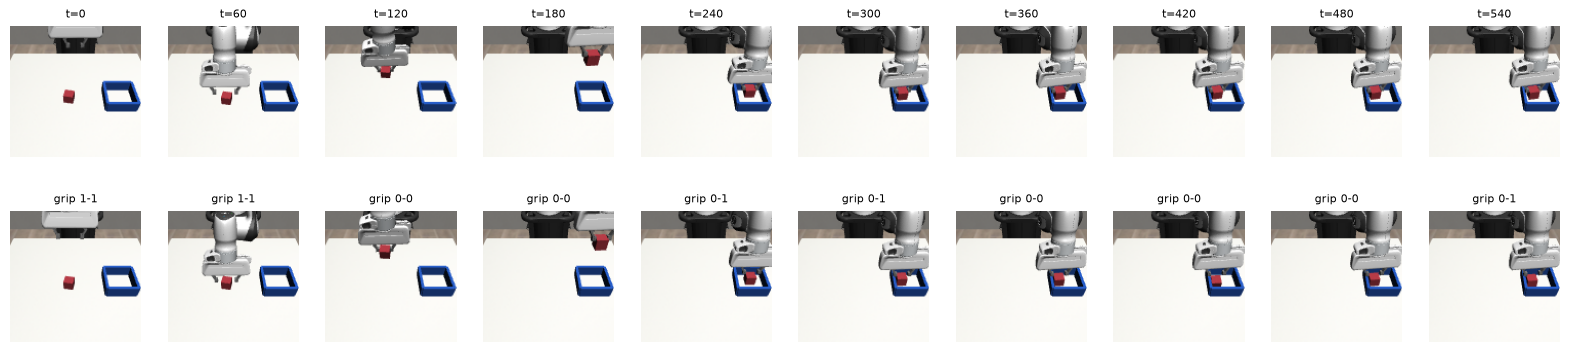

In [54]:
every = log[::6]  # the whole episode, every 60 steps
fig, axs = plt.subplots(2, len(every), figsize=(2 * len(every), 4.4))
for j, (t, now, fut, grip) in enumerate(every):
    axs[0, j].imshow(now)
    axs[0, j].set_title(f't={t}', fontsize=8)
    axs[1, j].imshow(fut)
    axs[1, j].set_title(f'grip {grip.min():.0f}-{grip.max():.0f}', fontsize=8)
for ax in axs.flat:
    ax.axis('off')

In [75]:
print('expert phase at the end:', expert.phase)
print(
    'hand z',
    env.mujoco[1].site('gripper0_right_grip_site').xpos[2].round(3),
    ' cube z',
    env.cube_pos[2].round(3),
)

expert phase at the end: approach
hand z 0.953  cube z 0.82


Video of the failed seed: left the real camera, right the dream the current plan aims at.


In [76]:
def rollout_frames(seed, net):
    # rollout(), keeping every step's [real frame | current dream], 2x upscaled
    obs = env.reset(seed=seed)
    expert.reset()
    frames = []
    for t in range(600):
        if t % net.k == 0:
            fut = imagine(obs, net.k)
            plan = idm_act(net, obs, fut)
        pair = np.concatenate([obs.images['top'], fut.images['top']], 1)
        frames.append(pair.repeat(2, 0).repeat(2, 1))
        expert(obs)
        res = env.step(plan[t % net.k])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    return frames

In [57]:
import imageio
from IPython.display import Video

imageio.mimsave('../scratch/idm_seed1009.mp4', rollout_frames(1009, net), fps=20)
Video('../scratch/idm_seed1009.mp4', embed=True, width=512)

## Step 13: dream every 16 steps

The release takes 8-10 steps to open the fingers past the expert's threshold, so a dream 10
ahead lands right at the edge. An IDM trained on 16-step gaps; dream 16 ahead, play 16.


In [90]:
run16 = train_idm(k=16)

train_idm: result copied by keep=True from older code (cell a1a6e7f7d391)
 1000  train 0.0093   val arm 0.00013  gripper right 99.4%
 2000  train 0.0083   val arm 0.00008  gripper right 99.6%
 3000  train 0.0065   val arm 0.00006  gripper right 99.6%
 4000  train 0.0040   val arm 0.00005  gripper right 99.6%
 5000  train 0.0054   val arm 0.00005  gripper right 99.7%
 6000  train 0.0027   val arm 0.00004  gripper right 99.6%
 7000  train 0.0038   val arm 0.00004  gripper right 99.6%
 8000  train 0.0027   val arm 0.00004  gripper right 99.6%
 9000  train 0.0030   val arm 0.00004  gripper right 99.6%
10000  train 0.0033   val arm 0.00004  gripper right 99.6%


In [70]:
net16 = IDM(16).to(dev)
net16.load_state_dict(run16['weights'])
res16 = {seed: rollout(seed, net16) for seed in range(1000, 1020)}
print(f'oracle IDM, k=16: {sum(s for s, _ in res16.values())}/20')
print('failures', Counter(m for s, m in res16.values() if not s))

oracle IDM, k=16: 14/20
failures Counter({'no_grasp': 4, 'wrong_target': 2})


In [71]:
print('k=10 failed', [s for s, (ok, _) in res.items() if not ok])
print('k=16 failed', {s: m for s, (ok, m) in res16.items() if not ok})

k=10 failed [1009]
k=16 failed {1002: 'wrong_target', 1008: 'wrong_target', 1009: 'no_grasp', 1010: 'no_grasp', 1012: 'no_grasp', 1015: 'no_grasp'}


In [73]:
log16 = rollout_log(1010, net16)

seed 1010: 600 steps, success False, no_grasp


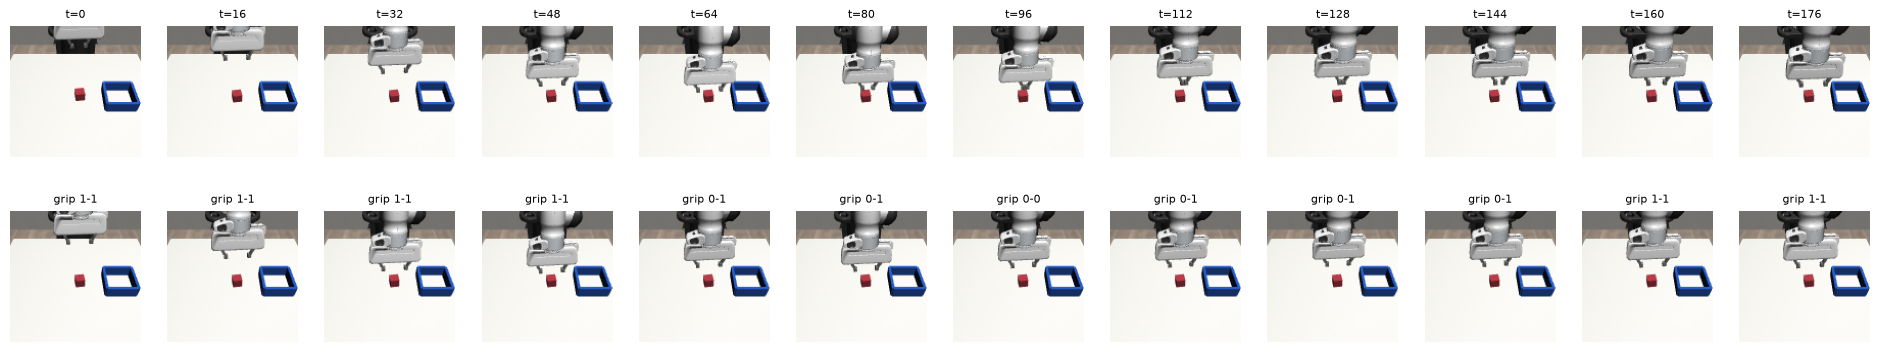

In [74]:
first = log16[:12]
fig, axs = plt.subplots(2, len(first), figsize=(2 * len(first), 4.4))
for j, (t, now, fut, grip) in enumerate(first):
    axs[0, j].imshow(now)
    axs[0, j].set_title(f't={t}', fontsize=8)
    axs[1, j].imshow(fut)
    axs[1, j].set_title(f'grip {grip.min():.0f}-{grip.max():.0f}', fontsize=8)
for ax in axs.flat:
    ax.axis('off')

Videos, k=16: seed 1010 (no_grasp), seed 1002 (wrong_target). Left real, right the dream.


In [79]:
imageio.mimsave('../scratch/idm16_seed1010.mp4', rollout_frames(1010, net16), fps=20)
Video('../scratch/idm16_seed1010.mp4', embed=True, width=512)

In [78]:
imageio.mimsave('../scratch/idm16_seed1002.mp4', rollout_frames(1002, net16), fps=20)
Video('../scratch/idm16_seed1002.mp4', embed=True, width=512)

## Step 14: is the IDM wrong on states the demos never show?

Every dream comes with its answer: the expert's own actions on the way there. Along a failed
rollout, compare the IDM's plan with them at every dream point (val error on demo states: arm 0.00003).


In [80]:
def imagine_answer(obs, k):
    # imagine(), also returning the expert's actions on the way -> (observation, [n, 8])
    snap = snapshot()
    acts = []
    for _ in range(k):
        acts.append(expert(obs)[0])
        res = env.step(acts[-1])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    restore(snap)
    return obs, np.array(acts)

In [81]:
def rollout_err(seed, net):
    # rollout(), logging per dream point: t, arm error vs the expert, gripper (plan, expert) means
    obs = env.reset(seed=seed)
    expert.reset()
    rows = []
    for t in range(600):
        if t % net.k == 0:
            fut, answer = imagine_answer(obs, net.k)
            plan = idm_act(net, obs, fut)
            n = len(answer)
            arm = ((plan[:n, :7] - answer[:, :7]) ** 2).mean()
            rows.append((t, arm, plan[:n, 7].round().mean(), answer[:, 7].mean()))
        expert(obs)
        res = env.step(plan[t % net.k])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    print(f'seed {seed}, k={net.k}: success {res.success}, {res.failure_mode}')
    return np.array(rows)

In [86]:
errs = {'k=10, seed 1009': rollout_err(1009, net), 'k=16, seed 1002': rollout_err(1002, net16)}

seed 1009, k=10: success False, wrong_target
seed 1002, k=16: success False, wrong_target


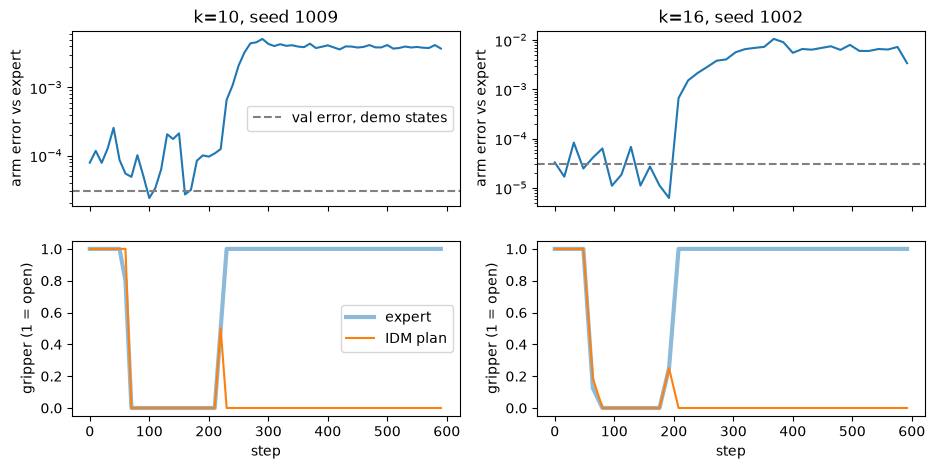

In [87]:
fig, axs = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for j, (name, e) in enumerate(errs.items()):
    axs[0, j].semilogy(e[:, 0], e[:, 1])
    axs[0, j].axhline(3e-5, color='gray', ls='--', label='val error, demo states')
    axs[0, j].set_title(name)
    axs[0, j].set_ylabel('arm error vs expert')
    axs[1, j].plot(e[:, 0], e[:, 3], label='expert', lw=3, alpha=0.5)
    axs[1, j].plot(e[:, 0], e[:, 2], label='IDM plan')
    axs[1, j].set_ylabel('gripper (1 = open)')
    axs[1, j].set_xlabel('step')
axs[0, 0].legend()
axs[1, 0].legend()

## Step 15: DAgger, labels from the oracle

The k=10 IDM drives 50 training seeds (0-49, not the eval seeds). At every dream point keep
(frame now, dream, joints, the expert's actions to the dream): right answers on the states the
IDM itself reaches, stuck ones included. Retrain with these as half of every batch.


In [93]:
@cache
def collect(n: int = 50):
    # IDM rollouts on env seeds 0..n-1 -> rows now, fut [N, 3, 128, 128] uint8, state [N, 8], act [N, K, 8]
    rows = {'now': [], 'fut': [], 'state': [], 'act': []}
    wins = 0
    for seed in range(n):
        obs = env.reset(seed=seed)
        expert.reset()
        for t in range(600):
            if t % K == 0:
                fut, answer = imagine_answer(obs, K)
                plan = idm_act(net, obs, fut)
                if len(answer) == K:
                    rows['now'].append(obs.images['top'].transpose(2, 0, 1))
                    rows['fut'].append(fut.images['top'].transpose(2, 0, 1))
                    rows['state'].append(obs.state)
                    rows['act'].append(answer)
            expert(obs)
            res = env.step(plan[t % K])
            obs = res.observation
            if res.terminated or res.truncated:
                break
        wins += res.success
    print(f'{wins}/{n} rollouts succeeded, {len(rows["act"])} rows')
    return frozendict(
        {
            name: np.array(v, dtype=np.uint8 if name in ('now', 'fut') else np.float32)
            for name, v in rows.items()
        }
    )

collect: not cached, will compute


In [94]:
dag = collect()

48/50 rollouts succeeded, 1134 rows


In [95]:
run_d = train_idm(extra=dag)

 1000  train 0.0116   val arm 0.00013  gripper right 99.3%
 2000  train 0.0053   val arm 0.00009  gripper right 99.6%
 3000  train 0.0056   val arm 0.00007  gripper right 99.6%
 4000  train 0.0036   val arm 0.00007  gripper right 99.6%
 5000  train 0.0025   val arm 0.00006  gripper right 99.6%
 6000  train 0.0030   val arm 0.00006  gripper right 99.5%
 7000  train 0.0028   val arm 0.00005  gripper right 99.6%
 8000  train 0.0023   val arm 0.00005  gripper right 99.5%
 9000  train 0.0032   val arm 0.00005  gripper right 99.6%
10000  train 0.0029   val arm 0.00005  gripper right 99.6%


In [96]:
net_d = IDM().to(dev)
net_d.load_state_dict(run_d['weights'])
res_d = {seed: rollout(seed, net_d) for seed in range(1000, 1020)}
print(f'oracle IDM + DAgger: {sum(s for s, _ in res_d.values())}/20')
print('failures', {s: m for s, (ok, m) in res_d.items() if not ok})

oracle IDM + DAgger: 17/20
failures {1007: 'no_grasp', 1009: 'wrong_target', 1010: 'no_grasp'}
